# Baseline: default Spraypoint

What does the network look like with no bypass? This sets the numbers the bypass has to beat.

Reads `experiments/results/tcp-baseline-load-sweep/`, so it shows whatever runs have finished. Rerun it as more arrive.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import common

common.setup_plots()
pd.options.display.float_format = "{:,.2f}".format

runs = common.load_runs(common.BASELINE_EXPERIMENT)
flows = common.load_flows(runs)
links = common.load_links(runs)
print(f"{len(runs)} finished runs, loads {sorted({r.load for r in runs})}, seeds {sorted({r.seed for r in runs})}")

1 finished runs, loads [0.1], seeds [561]


## Are the runs healthy?

`unfinished`, `ttl_drops` and `no_route_drops` should all be 0. Queue drops are normal under load.

In [2]:
health = common.runs_table(runs)
display(health)

problems = health[(health["unfinished"] > 0) | (health["ttl_drops"] > 0) | (health["no_route_drops"] > 0)]
print("All runs healthy" if problems.empty else f"Check these runs:\n{problems}")

,run,bypass,load,seed,flows,unfinished,ttl_drops,no_route_drops,queue_drops,wall_minutes,peak_memory_mb,commit
0,load-0.1_seed-561,none,0.10,561,47145,0,0,0,165,2.70,927,41e773f


All runs healthy


## Flow completion times

Pooled across seeds, leaving out flows that start in the first and last 10% of a run, when the network sees less load. `beyond_p99` is how many flows the p99 rests on: below about 100, treat it as noisy, and the same goes for p99.9 at 10 times that flow count.

In [3]:
display(common.fct_table(flows, ["class", "load"]))

,,flows,unfinished,p50,p99,p99.9,beyond_p99
class,load,,,,,,
large,0.10,3685,0,179.17,269.94,340.47,36
small_adjacent,0.10,2123,0,9.99,17.49,24.80,21
small_other,0.10,31779,0,10.52,17.18,23.82,317


### The tail of the distribution

Each line shows the share of flows slower than a given time, so the far right of each panel is the tail. A jump near 1,000 µs or 10,000 µs is usually a retransmission timeout or a lost SYN, not queueing.

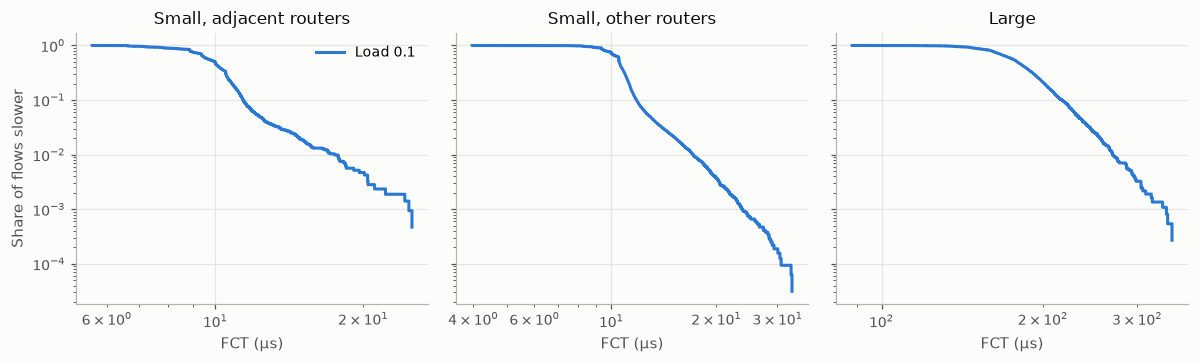

In [4]:
colors = common.load_colors(flows["load"])
figure, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for axis, flow_class in zip(axes, common.CLASSES):
    for load, group in flows[flows["class"] == flow_class].groupby("load"):
        x, y = common.tail_curve(group["fct_us"].to_numpy())
        axis.step(x, y, color=colors[load], label=f"Load {load:g}", where="post")
    axis.set(title=common.CLASS_NAMES[flow_class], xscale="log", yscale="log", xlabel="FCT (µs)")
axes[0].set_ylabel("Share of flows slower")
axes[0].legend()
figure.tight_layout()

## Paths

Share of delivered packets, including ACKs, at each number of fabric hops. Spraying means adjacent routers still mostly use long paths: this is the gap the bypass targets.

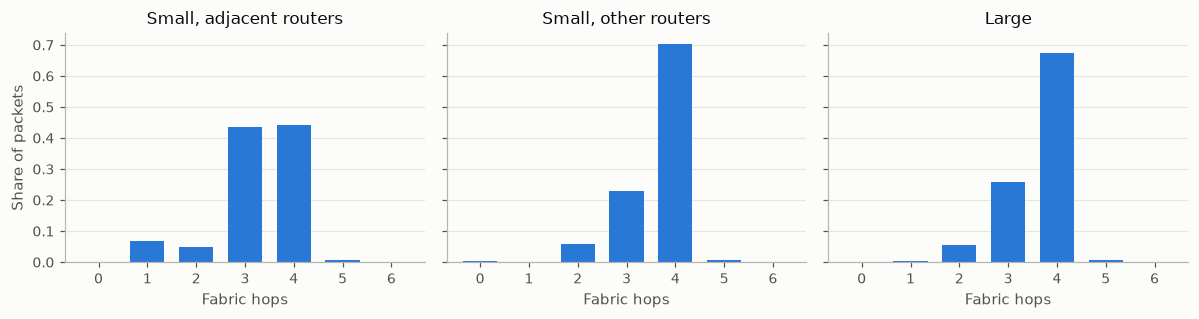

In [5]:
paths = common.path_table(runs).groupby(["class", "hops"])["fraction"].mean().reset_index()
figure, axes = plt.subplots(1, 3, figsize=(11, 3), sharey=True)
for axis, flow_class in zip(axes, common.CLASSES):
    data = paths[(paths["class"] == flow_class) & (paths["hops"] <= 6)]
    axis.bar(data["hops"], data["fraction"], color=common.MODE_COLORS["none"], width=0.7)
    axis.set(title=common.CLASS_NAMES[flow_class], xlabel="Fabric hops")
    axis.grid(axis="x", visible=False)
axes[0].set_ylabel("Share of packets")
figure.tight_layout()

## Links

How evenly does traffic spread? `hotspot_ratio` is the busiest link's utilization over the mean. This is the baseline for H2's question of whether the bypass creates hotspots.

In [6]:
display(common.link_table(links, ["load"]))

,mean_utilization,p99_utilization,max_utilization,hotspot_ratio,links_at_full_queue,mean_queue_packets
load,,,,,,
0.10,0.09,0.21,0.29,3.15,8,0.15


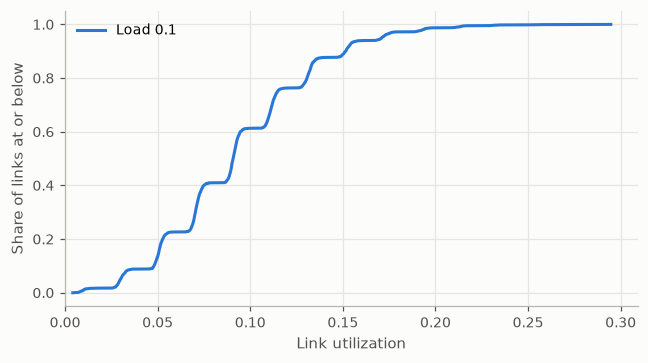

In [7]:
figure, axis = plt.subplots(figsize=(6, 3.4))
for load, group in links.groupby("load"):
    utilization = np.sort(group["utilization"].to_numpy())
    axis.plot(utilization, np.linspace(0, 1, len(utilization)), color=colors[load], label=f"Load {load:g}")
axis.set(xlabel="Link utilization", ylabel="Share of links at or below", xlim=(0, None))
axis.legend()
figure.tight_layout()

## Fan-in

Spraypoint should bring a destination's traffic in through many neighbors. `busiest_share` is the share of its traffic arriving from its busiest neighbor, and `neighbors` is how many deliver anything.

In [8]:
display(common.fan_in_table(links, ["load"]))

,busiest_share,neighbors
load,,
0.10,0.18,16.00
